# Capstone — mirrors the deployed research paper

This notebook walks the seven sections of the deployed paper, in order. Every headline number is recomputed here from the raw CSV, and each claim is framed as observed, measured, or decision-support — not causal.

Paper: https://saifsame7.github.io/FlyRank-Internship-/

## Social post & employer summary

### Social post (draft)

My content-decline model scored **0.90 precision@50** on a random split — then **0.74** when I held out entire clients. The second number is the honest one. On 30,000 anonymized pages from 32 clients, a random forest ranked refresh priorities at **0.74 precision@50 vs a 0.39 base rate** (+0.35 absolute, about 1.9×); method: client-level holdout, label-derived columns excluded, then added back deliberately to show the leak (0.999 accuracy — a red flag, not a win). Chart: Figure 1. Paper: https://saifsame7.github.io/FlyRank-Internship-/

### Employer-facing summary (3 sentences)

1. I built a client-holdout ranking model that flags content pages likely to be declining, so a small SEO team can review the right pages first.
2. I trained and evaluated it on 30,000 anonymized content pages from 32 pseudonymized clients in the FlyRank ML Internship dataset, holding out six clients entirely and excluding every label-derived column.
3. On unseen clients, the random forest reached **0.74 precision@50 against a 0.39 base rate** (0.75 ROC-AUC) while a transparent rule stayed at chance, and deliberately adding the label-derived `trend_pct` column pushed accuracy to 0.999 — confirming the leakage check.


## 1. Question

**Decision this supports.** Which content pages should an editor refresh first this week?

- **Unit of analysis:** one content page.
- **Output:** a decline-risk score and a ranked review queue.
- **Action a human takes:** an editor opens the top pages and decides to refresh, rewrite, or leave them.
- **Cost of a wrong call:** editor hours spent on pages that would not have declined, or a real decline missed because the page sat too far down the queue.

**Research question.** On clients the model has never seen, can a random forest rank declining pages better than a transparent rule and the base rate?

This is a ranking/triage problem, not a forecast of Google's algorithm. The label is an observed decline in the data window; the model is decision-support for where to look first.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "content_refresh_anonymized.csv").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
RAW_PATH = ROOT / "data" / "raw" / "content_refresh_anonymized.csv"
ASSET_DIR = ROOT / "docs" / "assets"
RANDOM_STATE = 42

df = pd.read_csv(RAW_PATH)
raw_columns = df.shape[1]
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)

print(f"rows={len(df):,}  columns={raw_columns}  pseudonymous clients={df['client_id'].nunique()}")
print(f"decline base rate (overall) = {df['is_declining_label'].mean():.2%}")

rows=30,000  columns=44  pseudonymous clients=32
decline base rate (overall) = 54.21%


## 2. Data

**Release.** The FlyRank ML Internship anonymized content-refresh teaching slice: 30,000 rows × 44 columns, one row per content page, from 32 pseudonymized clients. Performance is summarized over 90-day windows (`impressions_90d`, `clicks_90d`, …), with separate `*_last_30d` and `*_prev_30d` columns.

**What we excluded, and why.**
- `trend_direction` and `trend_pct` — the label is defined from `trend_direction`, so both are label-derived and can never be features.
- `impressions_last_30d`, `clicks_last_30d`, `sessions_last_30d` — the last-30-day window overlaps the label window, so they leak the outcome.
- `client_id` / `content_id` — pseudonyms used only for grouping and the client split, never as model inputs.

**Public safety.** No client names, URLs, or raw queries appear here or in the paper. Every number below is an aggregate over pseudonymized rows.

**Data quirks we kept.** Rate columns are stored ×100 (`ctr = 0.76` means 0.76%); `avg_position = 0` means "no data"; `scroll_rate` and `ai_traffic_pct` can exceed 100%; missingness is not random — it follows `content_type`. We fill missing numerics with 0 and label missing categories `unknown`, which is a modeling choice, not a claim that the value is truly zero.

In [2]:
inventory = pd.Series(
    {
        "rows": f"{len(df):,}",
        "columns": f"{raw_columns}",
        "pseudonymous_clients": f"{df['client_id'].nunique()}",
        "decline_base_rate": f"{df['is_declining_label'].mean():.4f}",
        "rows_labelled_down": f"{int(df['is_declining_label'].sum()):,}",
    },
    dtype="object",
)
display(inventory.to_frame("value"))

excluded = [
    "trend_direction",
    "trend_pct",
    "impressions_last_30d",
    "clicks_last_30d",
    "sessions_last_30d",
]
print("Columns excluded from the honest feature set:")
for column in excluded:
    print(" -", column)

miss = df.isna().mean().sort_values(ascending=False)
print("\nColumns with missing values (share of rows):")
if (miss > 0).any():
    print(miss[miss > 0].round(4).to_string())
    top_missing = miss[miss > 0].index[0]
    by_type = (
        df.groupby("content_type")[top_missing]
        .apply(lambda s: round(s.isna().mean(), 3))
        .sort_values(ascending=False)
    )
    print(f"\nMissing `{top_missing}` share by content_type (missingness follows content type):")
    print(by_type.to_string())
else:
    print("No missing values in the slice.")

,value
rows,"30,000"
columns,44
pseudonymous_clients,32
decline_base_rate,0.5421
rows_labelled_down,"16,262"


Columns excluded from the honest feature set:
 - trend_direction
 - trend_pct
 - impressions_last_30d
 - clicks_last_30d
 - sessions_last_30d

Columns with missing values (share of rows):
provider_used        0.7146
char_count           0.2566
word_count           0.2566
word_count_tier      0.2566
char_count_tier      0.2566
model_used           0.1911
trend_pct            0.1129
competition_level    0.0870
cpc                  0.0823
competition          0.0823
search_volume        0.0823
main_intent          0.0791
scroll_rate          0.0042

Missing `provider_used` share by content_type (missingness follows content type):
content_type
comparison article    0.834
keyword article       0.713
feedly article        0.700


## 3. Methodology

**Assumptions.**
1. `trend_direction == "down"` is a usable proxy for "this page is declining" — it is an observed label from the data window, not a future outcome.
2. Client identity should not carry signal; the honest test therefore holds out whole clients.
3. A page's 90-day visibility, position, age, and freshness are legitimate pre-decision signals.

**Features (52 total).** 18 numeric: search volume, competition, CPC, word/char counts, log counts of 90-day impressions/clicks/sessions/AI sessions, days with impressions/sessions, content age, days since update, CTR, average position, engagement rate, scroll rate, and AI traffic share. 8 categorical columns (competition level, content type, intent, age/freshness/word/impression/position tiers) are one-hot encoded.

**Label.** `is_declining_label = 1` when `trend_direction == "down"`, else 0. Overall base rate 54.21%; the held-out clients happen to be 39.1% declining.

**Baseline rule (built first).** Flag pages that are stale (`days_since_last_update >= 90`) **and** visible (`impressions_prev_30d >= median`); score = staleness × visibility × `impressions_prev_30d`. It is transparent, cheap, and a fair comparison because it uses only pre-decision columns.

**Validation design.** Client-level holdout: 6 of 32 clients (~20%) are held out entirely; the model trains on the other 26. We also show the random-row split only to measure how much it inflates the score.

**Leakage checks.** The same held-out split is re-fit after adding, one at a time, (a) `impressions_last_30d` (window overlap) and (b) `trend_pct` (label-derived). A jump toward 1.0 is proof of leakage, not skill.

**Models.** All-positive baseline, transparent rule, logistic regression, depth-5 decision tree, and a 200-tree random forest (`class_weight="balanced_subsample"`, `min_samples_leaf=25`, seed 42). Metrics: precision@50, ROC-AUC, average precision, accuracy.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

NUMERIC = [
    "search_volume", "competition", "cpc", "word_count", "char_count",
    "log_impressions_90d", "log_clicks_90d", "log_sessions_90d", "log_ai_sessions_90d",
    "days_with_impressions", "days_with_sessions", "content_age_days",
    "days_since_last_update", "ctr", "avg_position", "engagement_rate",
    "scroll_rate", "ai_traffic_pct",
]
CATEG = [
    "competition_level", "content_type", "main_intent", "age_tier",
    "freshness_tier", "word_count_tier", "impression_tier", "position_tier",
]

for name, source in {
    "log_impressions_90d": "impressions_90d",
    "log_clicks_90d": "clicks_90d",
    "log_sessions_90d": "sessions_90d",
    "log_ai_sessions_90d": "ai_sessions_90d",
}.items():
    df[name] = np.log1p(df[source])

num = df[NUMERIC].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0)
cat = df[CATEG].fillna("unknown").astype(str)
X = pd.concat(
    [num.reset_index(drop=True), pd.get_dummies(cat, prefix=CATEG, dtype=float).reset_index(drop=True)],
    axis=1,
)
y = df["is_declining_label"].astype(int)
print(f"honest feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features")


def precision_at_k(y_true, scores, k=50):
    frame = pd.DataFrame({"y": list(y_true), "s": list(scores)})
    top = frame.sort_values("s", ascending=False).head(min(k, len(frame)))
    return float(top["y"].mean()) if len(top) else 0.0


def score(y_true, prob):
    pred = (np.asarray(prob) >= 0.5).astype(int)
    return {
        "accuracy": round(float(accuracy_score(y_true, pred)), 4),
        "precision_at_50": round(precision_at_k(y_true, prob), 4),
        "roc_auc": round(float(roc_auc_score(y_true, prob)), 4),
        "avg_precision": round(float(average_precision_score(y_true, prob)), 4),
    }


def holdout_indices(frame, seed):
    rng = np.random.default_rng(seed)
    clients = frame["client_id"].astype(str).unique()
    shuffled = rng.permutation(clients)
    test_clients = set(shuffled[: max(1, round(len(shuffled) * 0.2))])
    mask = frame["client_id"].astype(str).isin(test_clients).to_numpy()
    return np.where(~mask)[0], np.where(mask)[0]


train_idx, test_idx = holdout_indices(df, RANDOM_STATE)
print(
    f"train rows={len(train_idx):,}  test rows={len(test_idx):,}  "
    f"train base rate={y.iloc[train_idx].mean():.2%}  test base rate={y.iloc[test_idx].mean():.2%}"
)

stale = (df["days_since_last_update"] >= 90).astype(float)
visible = (df["impressions_prev_30d"] >= df["impressions_prev_30d"].median()).astype(float)
rule_score = (stale * visible * df["impressions_prev_30d"]).to_numpy()


def make_rf(seed):
    return RandomForestClassifier(
        class_weight="balanced_subsample",
        max_depth=10,
        min_samples_leaf=25,
        n_estimators=200,
        n_jobs=-1,
        random_state=seed,
    )


models = {
    "logistic_regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "decision_tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE
    ),
    "random_forest": make_rf(RANDOM_STATE),
}

honest feature matrix: 30,000 rows x 52 features
train rows=27,675  test rows=2,325  train base rate=55.48%  test base rate=39.10%


## 4. Results (vs baseline)

All numbers below are on the same client-holdout split (2,325 rows from 6 unseen clients, 39.1% declining). Precision@50 asks: of the 50 pages we put at the top of the queue, how many were truly declining?

| Model | Precision@50 | ROC-AUC | Avg precision | Accuracy |
|---|---|---|---|---|
| All-positive baseline | 0.46 | 0.500 | 0.391 | 0.391 |
| Transparent rule | 0.46 | 0.501 | 0.392 | 0.610 |
| Logistic regression | 0.40 | 0.700 | 0.522 | 0.661 |
| Decision tree (depth 5) | 0.54 | 0.742 | 0.575 | 0.677 |
| **Random forest** | **0.74** | **0.750** | **0.618** | **0.672** |

**Headline.** The random forest lifts precision@50 from the 0.39 base rate to 0.74 — +0.35 absolute, about 1.9×. The transparent rule stays at chance on the top of the queue (0.46), so the learned ranking is doing real work.

**Why the random row split is not the headline.** On a random split the same model reaches 0.90 precision@50; holding out entire clients drops it to 0.74. The gap is client-level optimism, and 0.74 is the number we trust.

**Stability (5 seeds).** Repeating the client split and model across seeds 42, 7, 13, 2024, and 99 gives precision@50 = 0.832 ± 0.087 and ROC-AUC = 0.732 ± 0.060. The ranking is real but noisy at this sample size.

**Leakage confession.** Adding `impressions_last_30d` raises accuracy to 0.729; adding `trend_pct` pushes it to 0.9991. Both are leakage, and they are why those columns stay out of the honest feature set.

In [4]:
results = {
    "dummy_all_positive": score(y.iloc[test_idx], np.ones(len(test_idx))),
    "rule_baseline": score(y.iloc[test_idx], rule_score[test_idx]),
}
fitted = {}
for name, model in models.items():
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    fitted[name] = model
    results[name] = score(y.iloc[test_idx], model.predict_proba(X.iloc[test_idx])[:, 1])

table = pd.DataFrame(results).T[["precision_at_50", "roc_auc", "avg_precision", "accuracy"]]
print(f"held-out base rate = {y.iloc[test_idx].mean():.3f}   (n={len(test_idx):,} rows, 6 unseen clients)")
display(table)

rf_after = fitted["random_forest"]
tr_r, te_r = train_test_split(np.arange(len(df)), test_size=0.2, random_state=RANDOM_STATE, stratify=y)
rf_before = make_rf(RANDOM_STATE)
rf_before.fit(X.iloc[tr_r], y.iloc[tr_r])
before = score(y.iloc[te_r], rf_before.predict_proba(X.iloc[te_r])[:, 1])
after = score(y.iloc[test_idx], rf_after.predict_proba(X.iloc[test_idx])[:, 1])
print("\nOptimism check — same model, two splits:")
display(pd.DataFrame({"random_split": before, "client_holdout": after}).T)

leak_rows = [{"feature_set": "honest (used)", **after}]
for label, column in [
    ("+ impressions_last_30d (window overlap)", "impressions_last_30d"),
    ("+ trend_pct (label-derived)", "trend_pct"),
]:
    X_leak = X.copy()
    X_leak[f"{column}_suspect"] = df[column].fillna(0).to_numpy()
    rf_leak = make_rf(RANDOM_STATE)
    rf_leak.fit(X_leak.iloc[train_idx], y.iloc[train_idx])
    leak_rows.append(
        {"feature_set": label, **score(y.iloc[test_idx], rf_leak.predict_proba(X_leak.iloc[test_idx])[:, 1])}
    )
print("\nLeakage checks (same split, one suspect column added at a time):")
display(pd.DataFrame(leak_rows).set_index("feature_set")[["accuracy", "precision_at_50", "roc_auc"]])

stability = []
for seed in [42, 7, 13, 2024, 99]:
    tr, te = holdout_indices(df, seed)
    rf_s = make_rf(seed)
    rf_s.fit(X.iloc[tr], y.iloc[tr])
    stability.append(score(y.iloc[te], rf_s.predict_proba(X.iloc[te])[:, 1]))
stab = pd.DataFrame(stability)
print(
    f"\nStability across 5 seeds: precision@50 = {stab['precision_at_50'].mean():.3f} "
    f"± {stab['precision_at_50'].std(ddof=1):.3f}, "
    f"ROC-AUC = {stab['roc_auc'].mean():.3f} ± {stab['roc_auc'].std(ddof=1):.3f}"
)

holdout_df = df.iloc[test_idx].copy()
holdout_df["prob"] = rf_after.predict_proba(X.iloc[test_idx])[:, 1]
holdout_df["correct"] = ((holdout_df["prob"] >= 0.5).astype(int) == y.iloc[test_idx].to_numpy()).astype(int)
print("\nWhere the honest model still struggles — accuracy by content_type:")
display(holdout_df.groupby("content_type")["correct"].agg(["mean", "count"]).sort_values("mean"))
print("Accuracy by position_tier:")
display(holdout_df.groupby("position_tier")["correct"].agg(["mean", "count"]).sort_values("mean"))

held-out base rate = 0.391   (n=2,325 rows, 6 unseen clients)


,precision_at_50,roc_auc,avg_precision,accuracy
dummy_all_positive,0.46,0.5000,0.3910,0.3910
rule_baseline,0.46,0.5011,0.3919,0.6095
logistic_regression,0.40,0.7003,0.5215,0.6606
decision_tree,0.54,0.7415,0.5753,0.6766
random_forest,0.74,0.7500,0.6182,0.6723



Optimism check — same model, two splits:


,accuracy,precision_at_50,roc_auc,avg_precision
random_split,0.6920,0.90,0.7579,0.7684
client_holdout,0.6723,0.74,0.7500,0.6182



Leakage checks (same split, one suspect column added at a time):


,accuracy,precision_at_50,roc_auc
feature_set,,,
honest (used),0.6723,0.74,0.7500
+ impressions_last_30d (window overlap),0.7290,0.94,0.8427
+ trend_pct (label-derived),0.9991,1.00,1.0000



Stability across 5 seeds: precision@50 = 0.832 ± 0.087, ROC-AUC = 0.732 ± 0.060

Where the honest model still struggles — accuracy by content_type:


,mean,count
content_type,,
keyword article,0.595465,1367
feedly article,0.781837,958


Accuracy by position_tier:


,mean,count
position_tier,,
page_3_5,0.572954,281
striking,0.580247,405
page_1,0.618285,1061
deep,0.650000,60
top_3,0.911197,518


## 5. Limitations

- **The label is retrospective.** `trend_direction` is computed over the observed window. This notebook shows that declining pages are separable from the signals; it does not show the model predicts a future decline, and it makes no causal claim about Google.
- **Small client count.** Only 32 pseudonymized clients, and 6 are held out. Precision@50 is a 50-page slice of 2,325 rows and catches 37 of 909 declining pages, so ±0.09 across seeds is realistic.
- **Base rates differ.** Training clients are 55.5% declining, held-out clients are 39.1%. Ranking is the honest use; the 0.5 threshold and its accuracy are less meaningful than precision@50 and AUC.
- **Missingness is structural.** Gaps follow `content_type`; filling 0 / "unknown" is a choice that may bias specific content types.
- **No time-aware split.** A production system should validate on a later time window, not a random client split.
- **One baseline design.** The rule is transparent but not exhaustive; a better rule could close some of the gap.
- **Rates are stored ×100 and some share columns exceed 100%.** We treated them as provided; this is a data-quality caveat, not a modeling fix.

In [5]:
test_prob = rf_after.predict_proba(X.iloc[test_idx])[:, 1]
test_true = y.iloc[test_idx].to_numpy()
print("Threshold sensitivity on the held-out clients (accuracy hides the trade-off):")
rows = []
for cutoff in [0.3, 0.4, 0.5, 0.6]:
    pred = (test_prob >= cutoff).astype(int)
    tp = int(((pred == 1) & (test_true == 1)).sum())
    fp = int(((pred == 1) & (test_true == 0)).sum())
    fn = int(((pred == 0) & (test_true == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    rows.append(
        {
            "cutoff": cutoff,
            "flagged": int(pred.sum()),
            "precision": round(precision, 3),
            "recall": round(recall, 3),
        }
    )
display(pd.DataFrame(rows).set_index("cutoff"))

print(f"train base rate={y.iloc[train_idx].mean():.3f}  test base rate={y.iloc[test_idx].mean():.3f}")
print(f"precision@50 is measured on only 50 of {len(test_idx):,} held-out rows — a small, high-stakes slice.")
print(f"stability SD across 5 seeds = {stab['precision_at_50'].std(ddof=1):.3f} precision@50 points.")
print(f"client holdout = {df.iloc[test_idx]['client_id'].nunique()} of {df['client_id'].nunique()} clients.")

Threshold sensitivity on the held-out clients (accuracy hides the trade-off):


,flagged,precision,recall
cutoff,,,
0.3,1661,0.503,0.919
0.4,1501,0.520,0.859
0.5,1205,0.561,0.744
0.6,767,0.602,0.508


train base rate=0.555  test base rate=0.391
precision@50 is measured on only 50 of 2,325 held-out rows — a small, high-stakes slice.
stability SD across 5 seeds = 0.087 precision@50 points.
client holdout = 6 of 32 clients.


## 6. Ranked recommendations

Ranked by what a FlyRank editor should do first, given the held-out evidence:

1. **Use the random-forest score as a review queue, not an autopilot.** On unseen clients, 74% of the top-50 pages were truly declining versus a 39% base rate. Editors take the top 50 first; a human still decides refresh vs. rewrite vs. leave. That queue catches 37 of the 909 declining pages in the holdout — high-precision triage, not full coverage.
2. **Explain picks with the stale, high-visibility rule; don't rank with it.** The transparent rule (`days_since_last_update >= 90` and above-median `impressions_prev_30d`) is a cheap sanity check, but on its own it sits at chance on the top of the queue.
3. **Budget extra manual review for keyword articles.** The model is weakest there (≈0.60 accuracy), so those pages deserve a second look before action.
4. **Trust the score most on page-1 and top-3 positions.** Accuracy is highest for `top_3` (≈0.91) and `page_1` (≈0.62); deeper pages are where errors cluster.
5. **Re-validate on a later time window before production.** Treat every number here as decision-support measured on a 30k-row teaching slice, not a promise of future lift.

In [6]:
queue = df.iloc[test_idx].copy()
queue["decline_risk"] = rf_after.predict_proba(X.iloc[test_idx])[:, 1]
queue = queue.sort_values("decline_risk", ascending=False).reset_index(drop=True)
queue["first_action"] = np.where(
    queue["days_since_last_update"] >= 90, "Refresh + update", "Review / rewrite"
)

cols = [
    "content_type",
    "position_tier",
    "days_since_last_update",
    "impressions_90d",
    "avg_position",
    "decline_risk",
    "first_action",
]
print("Top 10 of the held-out review queue (pseudonymous rows; no client identifiers):")
display(queue[cols].head(10).round({"impressions_90d": 0, "avg_position": 2, "decline_risk": 3}))

top50 = queue.head(50)
print(
    f"\nTop-50 queue: {int((top50['decline_risk'] >= 0.5).sum())} pages scored >= 0.5; "
    f"{int(top50['is_declining_label'].sum())} of 50 truly declined "
    f"({top50['is_declining_label'].mean():.0%}, vs {y.iloc[test_idx].mean():.0%} base rate)."
)
print(
    f"Reviewing 50 pages instead of all {len(queue):,} catches "
    f"{int(top50['is_declining_label'].sum())} of the {int(y.iloc[test_idx].sum()):,} declining pages in the holdout."
)

Top 10 of the held-out review queue (pseudonymous rows; no client identifiers):


,content_type,position_tier,days_since_last_update,impressions_90d,avg_position,decline_risk,first_action
0,keyword article,top_3,8,767,3.0,0.768,Review / rewrite
1,keyword article,page_3_5,8,4908,29.1,0.763,Review / rewrite
2,keyword article,striking,8,405,10.6,0.763,Review / rewrite
3,keyword article,striking,8,682,15.1,0.754,Review / rewrite
4,keyword article,striking,8,337,13.9,0.753,Review / rewrite
5,keyword article,striking,20,524,15.1,0.750,Review / rewrite
6,keyword article,striking,20,2305,12.3,0.742,Review / rewrite
7,keyword article,page_3_5,20,3160,24.3,0.740,Review / rewrite
8,keyword article,striking,8,868,13.7,0.739,Review / rewrite
9,keyword article,page_1,20,372,7.6,0.739,Review / rewrite



Top-50 queue: 50 pages scored >= 0.5; 37 of 50 truly declined (74%, vs 39% base rate).
Reviewing 50 pages instead of all 2,325 catches 37 of the 909 declining pages in the holdout.


## 7. Artifacts the paper embeds

The deployed paper embeds four charts generated by `scripts/build_paper_assets.py`, plus a machine-readable `metrics.json`. The cell below reads the locked numbers and displays the charts so this notebook and the page agree.

Regenerate everything with:

```bash
python scripts/build_paper_assets.py
```

Locked metrics.json:
{
  "rows": 30000,
  "columns": 44,
  "clients": 32,
  "features": 52,
  "base_rate_overall": 0.5421,
  "test_rows": 2325,
  "test_base_rate": 0.391,
  "client_holdout": {
    "accuracy": 0.6723,
    "precision_at_50": 0.74,
    "roc_auc": 0.75,
    "avg_precision": 0.6182,
    "test_base_rate": 0.391
  },
  "random_split": {
    "accuracy": 0.692,
    "precision_at_50": 0.9,
    "roc_auc": 0.7579,
    "avg_precision": 0.7684,
    "test_base_rate": 0.542
  }
}

fig_before_after.png — 59 KB


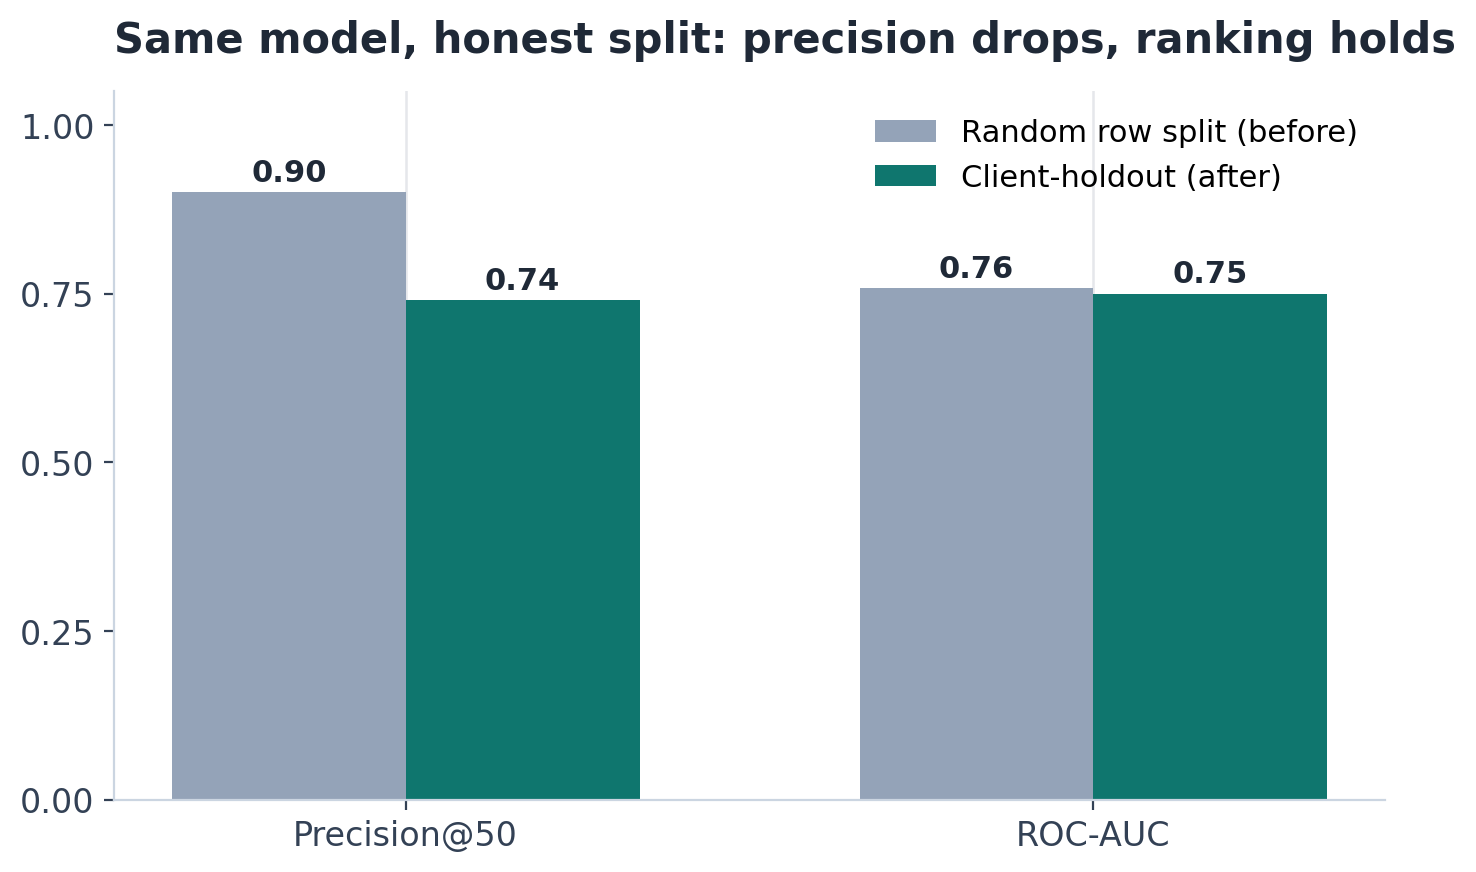


fig_model_vs_baseline.png — 93 KB


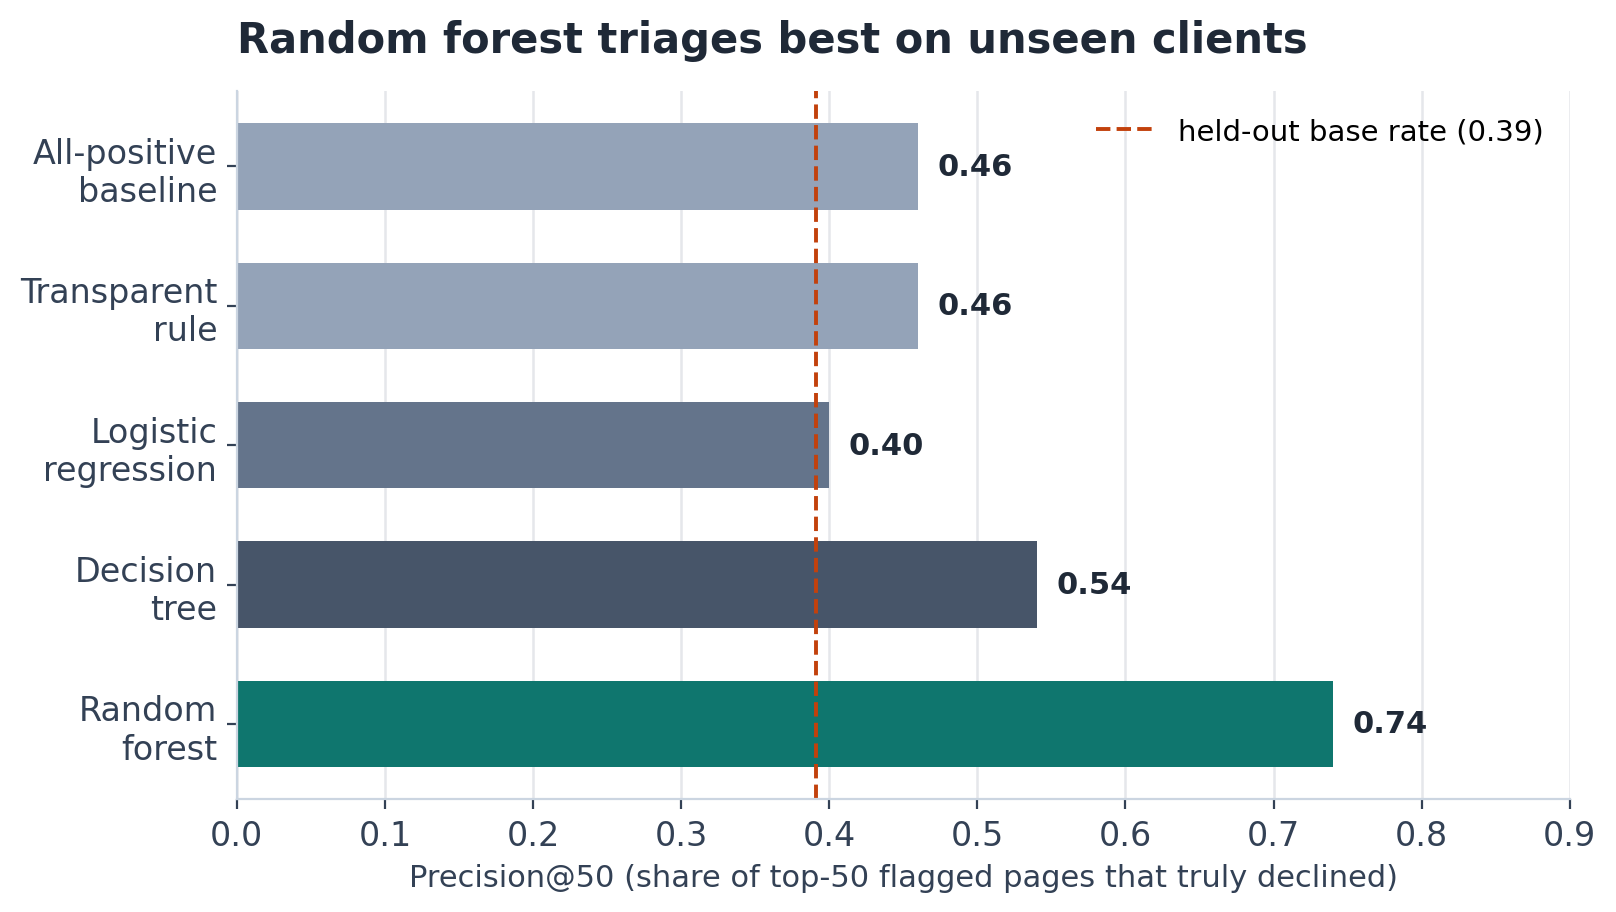


fig_leakage.png — 75 KB


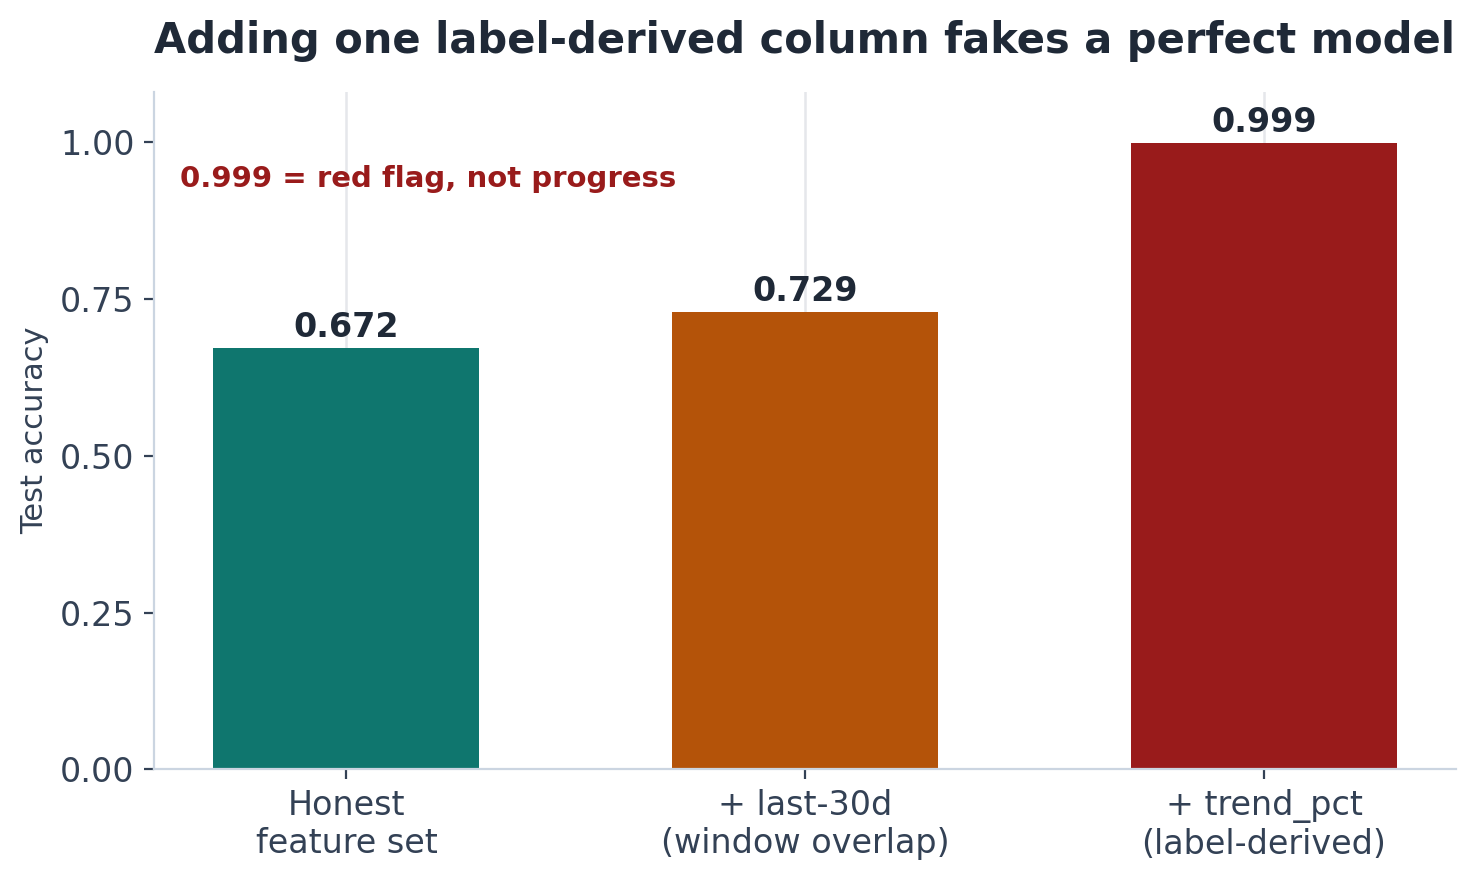


fig_feature_importance.png — 112 KB


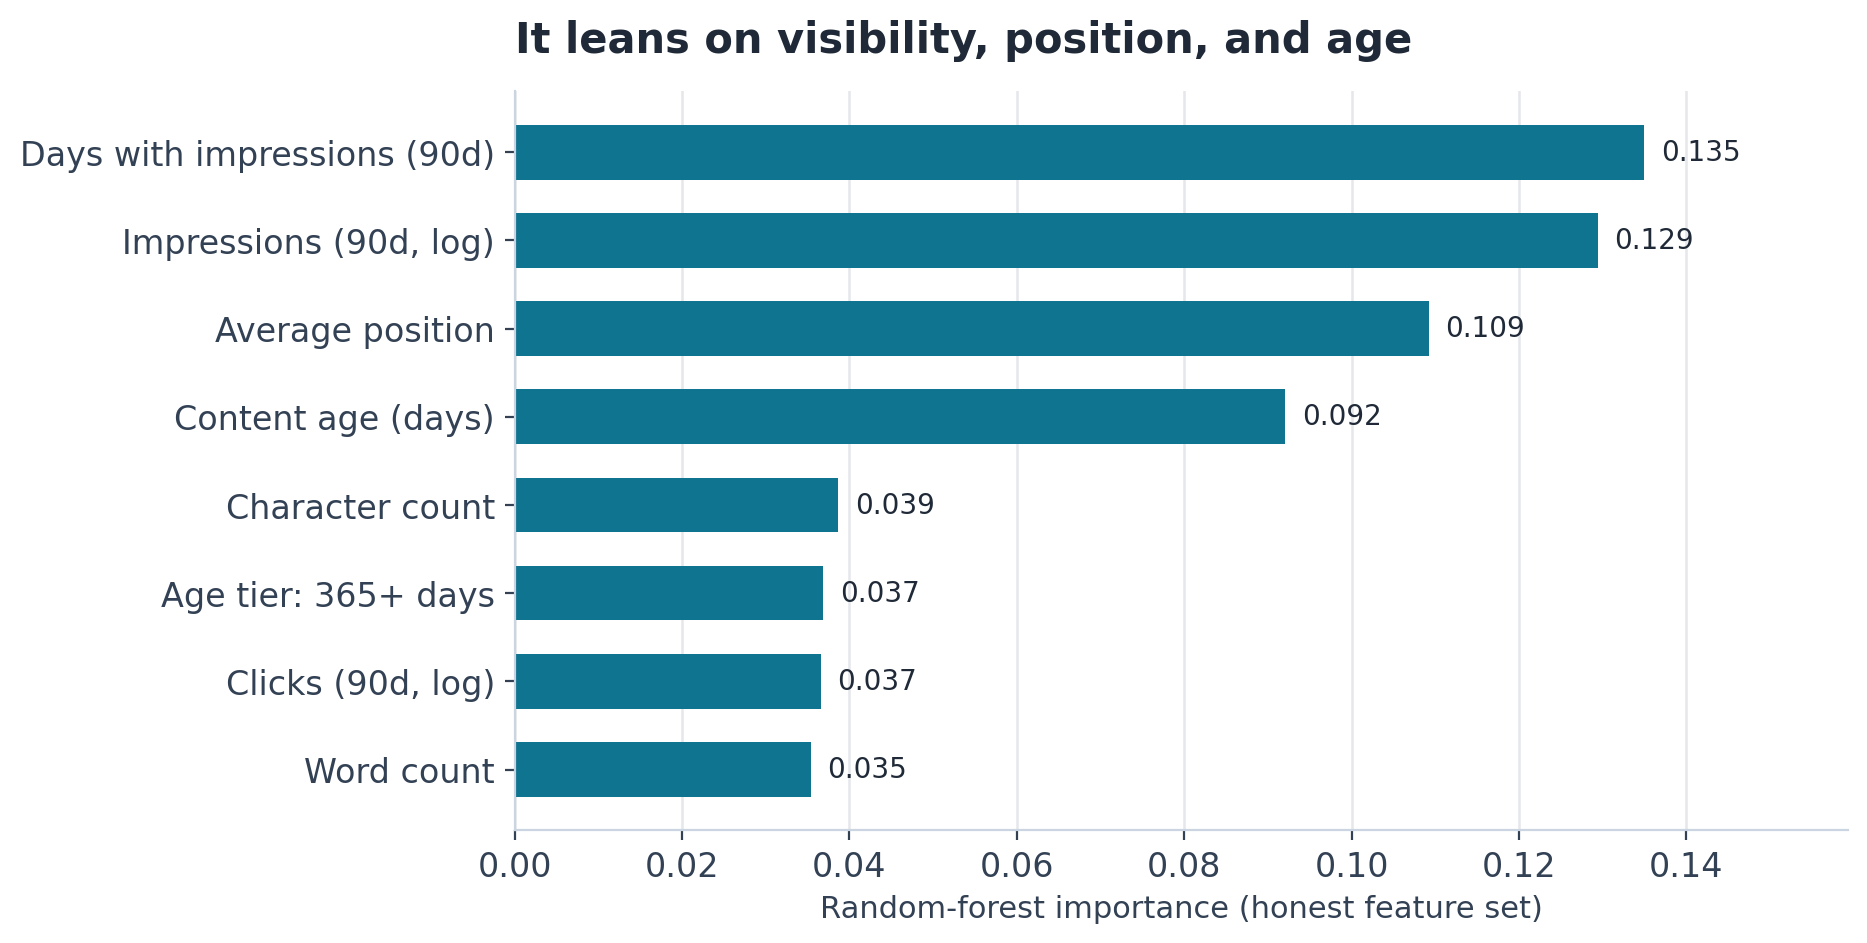

In [7]:
import json

metrics = json.loads((ASSET_DIR / "metrics.json").read_text(encoding="utf-8"))
keys = [
    "rows", "columns", "clients", "features", "base_rate_overall",
    "test_rows", "test_base_rate", "client_holdout", "random_split",
]
print("Locked metrics.json:")
print(json.dumps({k: metrics[k] for k in keys}, indent=2))

figures = [
    "fig_before_after.png",
    "fig_model_vs_baseline.png",
    "fig_leakage.png",
    "fig_feature_importance.png",
]
for name in figures:
    path = ASSET_DIR / name
    if path.exists():
        print(f"\n{name} — {path.stat().st_size // 1024} KB")
        display(Image(filename=str(path), width=620))
    else:
        print(f"\n{name} — MISSING (run scripts/build_paper_assets.py)")

## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (executed end-to-end with `nbclient`, kernel `python3`)
- [x] No client names, URLs, or private queries anywhere
- [x] Claims use careful words: observed, measured, directional, decision-support
- [x] Committed to the repo under `work/notebooks/`

**Reproducibility:** seed 42; install from `requirements.txt`; run `python scripts/build_paper_assets.py` to regenerate figures, then execute this notebook top to bottom.